In [122]:
#we start by importing our libraries, classes and all, the ones necessary to begin

In [123]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

In [124]:
#now, we go on to import our dataset

In [125]:
train_text = pd.read_json(r"C:\Users\DELL\Downloads\Training_data.json", lines = True)

In [126]:
train_text

,text,parent_comment,article_title,article_url,platform,platform_id,composite_toxic
0,"WTF, y'all never made MRE fart balloons in the...",None,Triangular UFO hovers over California military...,https://www.dailymail.co.uk/news/article-12112...,reddit,jlcm021,"[[False, 74], [True, 323], [False, 1028], [Fal..."
1,No apologies !! McCall has balls ! Ccp is not...,None,China sentences elderly US citizen to life in ...,https://www.cnn.com/2023/05/15/china/china-jai...,youtube,Ugws8gNW7eJyE9VHeM14AaABAg,"[[False, 216], [False, 197], [False, 1039], [F..."
2,What ever you need to tell yourself to sleep a...,I wonder how many undercover agents will be go...,Jan. 6 defendant who put foot on desk in Pelos...,https://www.cbsnews.com/news/richard-barnett-j...,youtube,UgxHlqwNcVssLHUr4yF4AaABAg.9q7kOunSlu-9q7lHH4he6S,"[[True, 192], [True, 193], [True, 260], [True,..."
3,@exZACKly @CBSNews Fuck off Nazi,@NCmylo @CBSNews Lol. Stop choosing to be an ...,19-year-old Missouri man arrested in U-Haul cr...,https://www.cbsnews.com/news/u-haul-crash-lafa...,twitter,1661025155047637000,"[[True, 92], [False, 218], [True, 69], [True, ..."
4,Texas is a republican sponsored killing ground...,None,At Least 8 Killed After Driver Plows Car Into ...,https://www.nytimes.com/2023/05/07/us/car-pede...,youtube,UgwpAfn9RIV0cHfhp4R4AaABAg,"[[False, 56], [True, 207], [False, 218], [Fals..."
...,...,...,...,...,...,...,...
3995,"Voluntary or not, won’t see my fat ass on any ...",Their ridership numbers are going to take a no...,Air New Zealand weighing passengers before flying,https://www.bbc.com/news/business-65765801,reddit,jmdgn83,"[[False, 81], [False, 184], [False, 248], [Fal..."
3996,So what?--*same party*. \n\nYou talk about hy...,May 2022. Whataboutisms. Haha. That was Kenny ...,Alberta declares state of emergency due to 'un...,https://edmonton.ctvnews.ca/alberta-declares-s...,reddit,jj7ixjw,"[[False, 46], [False, 89], [False, 112], [Fals..."
3997,@McKavitys Win stupid prizes! 😙,None,Bud Light parent company's stock downgraded by...,https://www.foxbusiness.com/markets/bud-light-...,twitter,1656631889661407233,"[[False, 95], [False, 45], [False, 323], [Fals..."
3998,@SIfill_ #DigitalSoldiers are afoot. An entire...,None,Atlanta police arrest 3 organizers behind bail...,https://www.pbs.org/newshour/politics/atlanta-...,twitter,1664307532570017795,"[[False, 182], [False, 196], [False, 33], [Fal..."


In [127]:
#now, our text has been loaded in, we go on to data cleaning

In [128]:
train_text.info

<bound method DataFrame.info of                                                    text  \
0     WTF, y'all never made MRE fart balloons in the...   
1     No apologies !! McCall has balls !  Ccp is not...   
2     What ever you need to tell yourself to sleep a...   
3                      @exZACKly @CBSNews Fuck off Nazi   
4     Texas is a republican sponsored killing ground...   
...                                                 ...   
3995  Voluntary or not, won’t see my fat ass on any ...   
3996  So what?--*same party*.  \n\nYou talk about hy...   
3997                 @McKavitys Win stupid prizes!    😙   
3998  @SIfill_ #DigitalSoldiers are afoot. An entire...   
3999  @grimsr3ap3r79 @I_Am_Illyria @Phil_Lewis_ fuck...   

                                         parent_comment  \
0                                                  None   
1                                                  None   
2     I wonder how many undercover agents will be go...   
3     @NCmylo @CBSNews 

In [129]:
train_text.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   text             4000 non-null   object
 1   parent_comment   1402 non-null   object
 2   article_title    4000 non-null   object
 3   article_url      4000 non-null   object
 4   platform         4000 non-null   object
 5   platform_id      4000 non-null   object
 6   composite_toxic  4000 non-null   object
dtypes: object(7)
memory usage: 218.9+ KB


In [130]:
train_text.isnull().sum()

text                  0
parent_comment     2598
article_title         0
article_url           0
platform              0
platform_id           0
composite_toxic       0
dtype: int64

In [131]:
#what we have seen is that our parent_comment has so many null values...
#we have to deal with that. since, it is an unnecessary column, i will go on to delete it

In [132]:
train_text.drop(columns = 'parent_comment', inplace = True)

In [133]:
train_text

,text,article_title,article_url,platform,platform_id,composite_toxic
0,"WTF, y'all never made MRE fart balloons in the...",Triangular UFO hovers over California military...,https://www.dailymail.co.uk/news/article-12112...,reddit,jlcm021,"[[False, 74], [True, 323], [False, 1028], [Fal..."
1,No apologies !! McCall has balls ! Ccp is not...,China sentences elderly US citizen to life in ...,https://www.cnn.com/2023/05/15/china/china-jai...,youtube,Ugws8gNW7eJyE9VHeM14AaABAg,"[[False, 216], [False, 197], [False, 1039], [F..."
2,What ever you need to tell yourself to sleep a...,Jan. 6 defendant who put foot on desk in Pelos...,https://www.cbsnews.com/news/richard-barnett-j...,youtube,UgxHlqwNcVssLHUr4yF4AaABAg.9q7kOunSlu-9q7lHH4he6S,"[[True, 192], [True, 193], [True, 260], [True,..."
3,@exZACKly @CBSNews Fuck off Nazi,19-year-old Missouri man arrested in U-Haul cr...,https://www.cbsnews.com/news/u-haul-crash-lafa...,twitter,1661025155047637000,"[[True, 92], [False, 218], [True, 69], [True, ..."
4,Texas is a republican sponsored killing ground...,At Least 8 Killed After Driver Plows Car Into ...,https://www.nytimes.com/2023/05/07/us/car-pede...,youtube,UgwpAfn9RIV0cHfhp4R4AaABAg,"[[False, 56], [True, 207], [False, 218], [Fals..."
...,...,...,...,...,...,...
3995,"Voluntary or not, won’t see my fat ass on any ...",Air New Zealand weighing passengers before flying,https://www.bbc.com/news/business-65765801,reddit,jmdgn83,"[[False, 81], [False, 184], [False, 248], [Fal..."
3996,So what?--*same party*. \n\nYou talk about hy...,Alberta declares state of emergency due to 'un...,https://edmonton.ctvnews.ca/alberta-declares-s...,reddit,jj7ixjw,"[[False, 46], [False, 89], [False, 112], [Fals..."
3997,@McKavitys Win stupid prizes! 😙,Bud Light parent company's stock downgraded by...,https://www.foxbusiness.com/markets/bud-light-...,twitter,1656631889661407233,"[[False, 95], [False, 45], [False, 323], [Fals..."
3998,@SIfill_ #DigitalSoldiers are afoot. An entire...,Atlanta police arrest 3 organizers behind bail...,https://www.pbs.org/newshour/politics/atlanta-...,twitter,1664307532570017795,"[[False, 182], [False, 196], [False, 33], [Fal..."


In [134]:
#on further analysis, we see that the only important columns are the text and the composite_toxic columns, so let's drop others.

In [135]:
train_text = train_text[['text', 'composite_toxic']]

In [136]:
train_text

,text,composite_toxic
0,"WTF, y'all never made MRE fart balloons in the...","[[False, 74], [True, 323], [False, 1028], [Fal..."
1,No apologies !! McCall has balls ! Ccp is not...,"[[False, 216], [False, 197], [False, 1039], [F..."
2,What ever you need to tell yourself to sleep a...,"[[True, 192], [True, 193], [True, 260], [True,..."
3,@exZACKly @CBSNews Fuck off Nazi,"[[True, 92], [False, 218], [True, 69], [True, ..."
4,Texas is a republican sponsored killing ground...,"[[False, 56], [True, 207], [False, 218], [Fals..."
...,...,...
3995,"Voluntary or not, won’t see my fat ass on any ...","[[False, 81], [False, 184], [False, 248], [Fal..."
3996,So what?--*same party*. \n\nYou talk about hy...,"[[False, 46], [False, 89], [False, 112], [Fals..."
3997,@McKavitys Win stupid prizes! 😙,"[[False, 95], [False, 45], [False, 323], [Fals..."
3998,@SIfill_ #DigitalSoldiers are afoot. An entire...,"[[False, 182], [False, 196], [False, 33], [Fal..."


In [137]:
#now, we are done with that.#we notice something about our composite_toxic columns , they are a list annotations, we have to deal with that.

In [138]:
def flatten_annotations(row) :
    annotations = [label for label, worker_id in row] 
    return sum(annotations) > (len(annotations)/2) 

In [139]:
train_text['composite_toxic'] = train_text['composite_toxic'].apply(flatten_annotations)

C:\Users\DELL\AppData\Local\Temp\ipykernel_14452\3921223872.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  train_text['composite_toxic'] = train_text['composite_toxic'].apply(flatten_annotations)


In [140]:
train_text

,text,composite_toxic
0,"WTF, y'all never made MRE fart balloons in the...",False
1,No apologies !! McCall has balls ! Ccp is not...,False
2,What ever you need to tell yourself to sleep a...,True
3,@exZACKly @CBSNews Fuck off Nazi,True
4,Texas is a republican sponsored killing ground...,False
...,...,...
3995,"Voluntary or not, won’t see my fat ass on any ...",False
3996,So what?--*same party*. \n\nYou talk about hy...,False
3997,@McKavitys Win stupid prizes! 😙,False
3998,@SIfill_ #DigitalSoldiers are afoot. An entire...,False


In [141]:
train_text= train_text.rename(columns = {"composite_toxic": 'label'})

In [142]:
train_text

,text,label
0,"WTF, y'all never made MRE fart balloons in the...",False
1,No apologies !! McCall has balls ! Ccp is not...,False
2,What ever you need to tell yourself to sleep a...,True
3,@exZACKly @CBSNews Fuck off Nazi,True
4,Texas is a republican sponsored killing ground...,False
...,...,...
3995,"Voluntary or not, won’t see my fat ass on any ...",False
3996,So what?--*same party*. \n\nYou talk about hy...,False
3997,@McKavitys Win stupid prizes! 😙,False
3998,@SIfill_ #DigitalSoldiers are afoot. An entire...,False


In [143]:
#we have been able to do some cleaning, let's go on to exploratory data analysis

In [144]:
train_text['label'].value_counts()

label
False    2974
True     1026
Name: count, dtype: int64

Text(0.5, 1.0, 'Distribution of Labels before balancing')

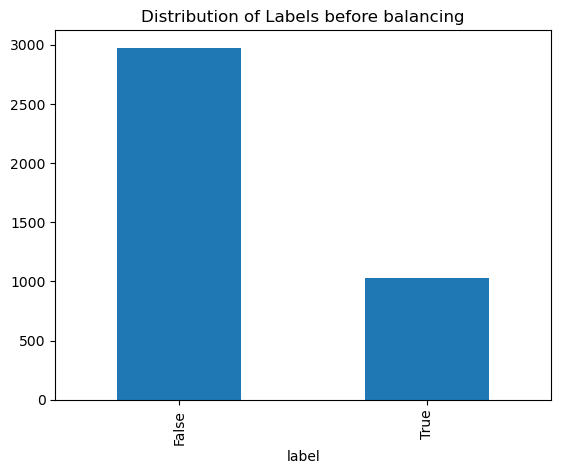

In [145]:
train_text['label'].value_counts().plot(kind = 'bar')
plt.title('Distribution of Labels before balancing')

In [146]:
import re
import nltk
from nltk.stem import PorterStemmer
from nltk.corpus import stopwords
nltk.download('stopwords')
port_stem = PorterStemmer()

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\DELL\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [147]:
def port_stemming(content):
    stemmed_content = re.sub(r'[^a-zA-Z]', ' ', content)
    stemmed_content = stemmed_content.lower()
    stemmed_content = stemmed_content.split()
    stemmed_content = [port_stem.stem(word) for word in stemmed_content if not word in stopwords.words('english')]
    stemmed_content = ' '.join(stemmed_content)
    return stemmed_content

In [148]:
train_text['stemmed_text'] = train_text['text'].apply(port_stemming)

In [149]:
from nltk.stem import WordNetLemmatizer  #didn't work as much as we expected it to, so we sort of abandoned it coz it still
lemmatizer = WordNetLemmatizer()         #maintained suffixes and words in their adverbial forms.

nltk.download('wordnet')

def lemming(content):
    lemma_content = re.sub(r'[^a-zA-Z]', ' ', content)
    lemma_content = lemma_content.lower()
    lemma_content = lemma_content.split()
    lemma_content = [lemmatizer.lemmatize(word) for word in lemma_content if not word in stopwords.words('english')]
    lemma_content = ' '.join(lemma_content)
    return lemma_content

[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\DELL\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


In [150]:
train_text['lemmatized_text'] = train_text['text'].apply(lemming)

In [151]:
x= train_text['stemmed_text']
y= train_text['label']

In [152]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [153]:
#next we vectorize our text using tfidf vectorizer

from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer 

tfidf = TfidfVectorizer()
x_train_ = tfidf.fit_transform(x_train)
x_test = tfidf.transform(x_test)

In [154]:
#we also encode our labels using label encoder, it's safe since we are just iterating through two items

from sklearn.preprocessing import LabelEncoder 
le = LabelEncoder()


y_train = le.fit_transform(y_train)
y_test = le.transform(y_test)

In [155]:
#now, we are all set to start prediction,
#i'd run multiple experiments to see which works best...
#i'd start with baseline, that's no balancing of my dataset, just raw as it is

In [156]:
# Import sklearn metrics to evaluate model performance
from sklearn.metrics import classification_report #summary showing the metrics
from sklearn.metrics import confusion_matrix  #tp,fp, tn, fn
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import roc_auc_score

In [157]:
from sklearn.linear_model import LogisticRegression    # For Logistic Regression model
from sklearn.naive_bayes import MultinomialNB    

Log = LogisticRegression()
Nb = MultinomialNB()

In [158]:
#let's run the logistic regresion first

In [159]:
Log.fit(x_train_, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [160]:
base_prediction = Log.predict(x_train_)
base_classification_report = classification_report(y_train, base_prediction)
base_accuracy = accuracy_score(y_train, base_prediction)

In [161]:
print('Classification report of the Baseline Logistic Regression Model on the training data: \n\n', (base_classification_report))
print('Accuracy score of Baseline Logistic Regression Model on the training data: ', (base_accuracy))

Classification report of the Baseline Logistic Regression Model on the training data: 

               precision    recall  f1-score   support

           0       0.78      0.99      0.88      2379
           1       0.88      0.21      0.34       821

    accuracy                           0.79      3200
   macro avg       0.83      0.60      0.61      3200
weighted avg       0.81      0.79      0.74      3200

Accuracy score of Baseline Logistic Regression Model on the training data:  0.79


In [162]:

#let's do the hyper parameter tuning and test it on this baseline model too.

In [163]:
base_param_log = {   
    'C': [0.01, 0.1, 1, 10],
    'solver': ['liblinear', 'lbfgs'],
    'penalty': ['l2']
}

In [164]:
from sklearn.model_selection import GridSearchCV

base_tuning_log = GridSearchCV(
    estimator=LogisticRegression(max_iter=1000),
    param_grid=base_param_log,
    cv=5,
    scoring='f1',
    n_jobs=-1
)

base_tuning_log.fit(x_train_, y_train)

,estimator,LogisticRegre...max_iter=1000)
,param_grid,"{'C': [0.01, 0.1, ...], 'penalty': ['l2'], 'solver': ['liblinear', 'lbfgs']}"
,scoring,'f1'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,penalty,'l2'


In [165]:
print(base_tuning_log.best_params_)

{'C': 10, 'penalty': 'l2', 'solver': 'lbfgs'}


In [166]:
best_log_base = LogisticRegression(       #best_log_base = best tuned log model on baseline 
    C=10,
    penalty='l2',
    solver='lbfgs',
    max_iter=1000
)

best_log_base.fit(x_train_, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,10
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [167]:
tuned_base_prediction = best_log_base.predict(x_train_)
tuned_base_prediction_cr = classification_report(y_train, tuned_base_prediction)
tuned_base_prediction_accuracy = accuracy_score(y_train, tuned_base_prediction)
print('Classification report of Tuned Logistic Regression Model on the training data: \n\n',(tuned_base_prediction_cr))
print('Accuracy score of Tuned Logistic Regression Model on baseline training data: ', (tuned_base_prediction_accuracy))

Classification report of Tuned Logistic Regression Model on the training data: 

               precision    recall  f1-score   support

           0       0.98      0.99      0.99      2379
           1       0.98      0.95      0.96       821

    accuracy                           0.98      3200
   macro avg       0.98      0.97      0.97      3200
weighted avg       0.98      0.98      0.98      3200

Accuracy score of Tuned Logistic Regression Model on baseline training data:  0.980625


In [168]:
#Now to Naive Bayes

In [169]:
#let's do naive bayes raw

In [170]:
Nb.fit(x_train_, y_train)

,alpha,1.0
,force_alpha,True
,fit_prior,True
,class_prior,None


In [171]:
nb_base_prediction = Nb.predict(x_train_)
nb_base_prediction_cr = classification_report(y_train, nb_base_prediction)
nb_base_prediction_accuracy = accuracy_score(y_train, nb_base_prediction)
print('Classification report of Baseline Naive Bayes Model on the training data: \n\n',(nb_base_prediction_cr))
print('Accuracy score of Baseline Naive Bayes Model on baseline training data: ', (nb_base_prediction_accuracy))

Classification report of Baseline Naive Bayes Model on the training data: 

               precision    recall  f1-score   support

           0       0.77      1.00      0.87      2379
           1       0.99      0.11      0.20       821

    accuracy                           0.77      3200
   macro avg       0.88      0.56      0.53      3200
weighted avg       0.82      0.77      0.70      3200

Accuracy score of Baseline Naive Bayes Model on baseline training data:  0.771875


In [172]:
#now, the tuned naive bayes on base

In [173]:
base_param_nb = {
    'alpha': [0.01, 0.1, 0.5, 1, 2]
}

In [174]:
base_tuning_nb = GridSearchCV(
    MultinomialNB(),
    param_grid = base_param_nb,
    cv=5,
    scoring='f1'
)

base_tuning_nb.fit(x_train_, y_train)

,estimator,MultinomialNB()
,param_grid,"{'alpha': [0.01, 0.1, ...]}"
,scoring,'f1'
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,alpha,0.01


In [175]:
print(base_tuning_nb.best_params_)

{'alpha': 0.01}


In [176]:
best_nb_base = MultinomialNB(
    alpha= 0.01
)

best_nb_base.fit(x_train_, y_train)

,alpha,0.01
,force_alpha,True
,fit_prior,True
,class_prior,None


In [177]:
tuned_nb_base = best_nb_base.predict(x_train_)
tuned_nb_base_cr = classification_report(y_train, tuned_nb_base)
tuned_nb_base_accuracy = accuracy_score(y_train, tuned_nb_base)


print('Classification report of Naive Bayes Classification Model on Training Data after tuning baseline: \n\n', (tuned_nb_base_cr))
print('\n')
print('Accuracy score of Naive Bayes Model on the training data after tuning baseline: ', (tuned_nb_base_accuracy))

Classification report of Naive Bayes Classification Model on Training Data after tuning baseline: 

               precision    recall  f1-score   support

           0       0.96      0.99      0.98      2379
           1       0.97      0.89      0.93       821

    accuracy                           0.96      3200
   macro avg       0.97      0.94      0.95      3200
weighted avg       0.96      0.96      0.96      3200



Accuracy score of Naive Bayes Model on the training data after tuning baseline:  0.9646875


In [178]:
#now, we'll do just class weights for log model and fit prior for naive bayes model

In [179]:
class_weighted = LogisticRegression(
   class_weight="balanced",
    max_iter=5000,
    random_state=42)

class_weighted.fit(x_train_, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,'balanced'
,random_state,42
,solver,'lbfgs'
,max_iter,5000
,multi_class,'deprecated'


In [180]:
class_weighted_prediction = class_weighted.predict(x_train_)
class_weighted_prediction_cr = classification_report(y_train,class_weighted_prediction)
class_weighted_prediction_accuracy = accuracy_score(y_train,class_weighted_prediction)

print('Classification report of Logistic Regression model using class_weight hyperparameter on Training Data : \n\n', (class_weighted_prediction_cr))                                                                                                                                     
print('\n')
print('Accuracy score of Logistic Regression model using class_weight hyperparameter on the training data before tuning: ', (class_weighted_prediction_accuracy))


Classification report of Logistic Regression model using class_weight hyperparameter on Training Data : 

               precision    recall  f1-score   support

           0       0.98      0.89      0.93      2379
           1       0.75      0.94      0.83       821

    accuracy                           0.90      3200
   macro avg       0.86      0.91      0.88      3200
weighted avg       0.92      0.90      0.91      3200



Accuracy score of Logistic Regression model using class_weight hyperparameter on the training data before tuning:  0.9021875


In [181]:
#Let's now use fit prior = False for the naive bayes model

In [182]:
fit_prior_nb = MultinomialNB(
    fit_prior= False )

fit_prior_nb.fit(x_train_, y_train)

,alpha,1.0
,force_alpha,True
,fit_prior,False
,class_prior,None


In [183]:
fit_prior_prediction = fit_prior_nb.predict(x_train_)
fit_prior_prediction_cr = classification_report(y_train,fit_prior_prediction)
fit_prior_prediction_accuracy = accuracy_score(y_train, fit_prior_prediction)

print('Classification report of Naive Bayes Classification Model using fit_prior tuning on Training Data: \n\n', (fit_prior_prediction_cr ))
print('Accuracy score of Naive Bayes Model using fit_prior tuning  on the training data: ', (fit_prior_prediction_accuracy))

Classification report of Naive Bayes Classification Model using fit_prior tuning on Training Data: 

               precision    recall  f1-score   support

           0       0.88      0.97      0.92      2379
           1       0.87      0.61      0.72       821

    accuracy                           0.88      3200
   macro avg       0.87      0.79      0.82      3200
weighted avg       0.88      0.88      0.87      3200

Accuracy score of Naive Bayes Model using fit_prior tuning  on the training data:  0.876875


In [184]:
#now, we smote

In [185]:
import imblearn
from imblearn.over_sampling import SMOTE
from collections import Counter
smote = SMOTE()

x_train = x_train_
y_train = y_train

counter = Counter(y_train)

print("BEFORE...")
print(counter)
print()
print()

from imblearn import under_sampling, over_sampling

#thisis the application of the oversampling, remember it must be just to the training  data set and not the test data
x_train_smote, y_train_smote = smote.fit_resample(
    x_train,
    y_train.astype(str)
)


#Counter gives the actual value for each label so I can see it.

counter = Counter(y_train_smote)
print('AFTER...')
print(counter)

y_train_smote = y_train_smote.astype(int)

BEFORE...
Counter({np.int64(0): 2379, np.int64(1): 821})


AFTER...
Counter({np.str_('0'): 2379, np.str_('1'): 2379})


Text(0.5, 1.0, 'Distribution of Labels after applying SMOTE')

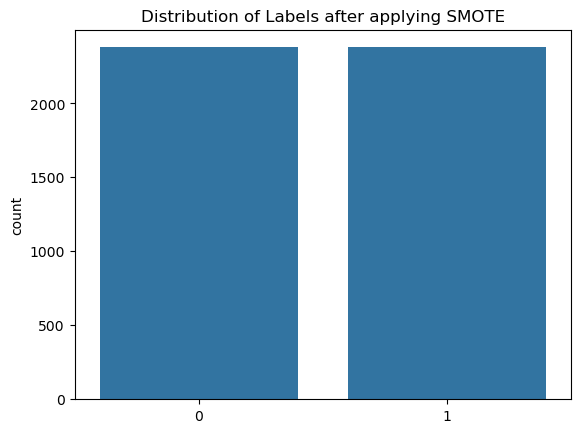

In [186]:
sns.countplot(x=y_train_smote)
plt.title('Distribution of Labels after applying SMOTE')

In [187]:
#now, let's try the smote log model without tuning

In [188]:
log_smote = LogisticRegression(max_iter = 1000)    #log_smote = smote log without tuning
log_smote.fit(x_train_smote, y_train_smote)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [189]:
log_smote_prediction = log_smote.predict(x_train_smote)
log_smote_prediction_cr = classification_report(y_train_smote, log_smote_prediction)
log_smote_prediction_accuracy = accuracy_score(y_train_smote, log_smote_prediction)


print('Classification report of the Logistic Regression Model on the smote training data before tuning: \n\n', (log_smote_prediction_cr))
print('Accuracy score of Logistic Regression Model on the smote training data before tuning: ', (log_smote_prediction_accuracy))

Classification report of the Logistic Regression Model on the smote training data before tuning: 

               precision    recall  f1-score   support

           0       0.89      0.91      0.90      2379
           1       0.90      0.89      0.90      2379

    accuracy                           0.90      4758
   macro avg       0.90      0.90      0.90      4758
weighted avg       0.90      0.90      0.90      4758

Accuracy score of Logistic Regression Model on the smote training data before tuning:  0.8984867591424969


In [190]:
#now, smote with tuning for log

In [191]:
smote_log_grid = {   
    'C': [0.01, 0.1, 1, 10],
    'solver': ['liblinear', 'lbfgs'],
    'penalty': ['l2']
}

In [192]:
tuned_log_smote = GridSearchCV(
    estimator=LogisticRegression(max_iter=5000),
    param_grid= smote_log_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1
)

tuned_log_smote.fit(x_train_smote, y_train_smote)

,estimator,LogisticRegre...max_iter=5000)
,param_grid,"{'C': [0.01, 0.1, ...], 'penalty': ['l2'], 'solver': ['liblinear', 'lbfgs']}"
,scoring,'f1'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,penalty,'l2'


In [193]:
print(tuned_log_smote.best_params_)

{'C': 10, 'penalty': 'l2', 'solver': 'lbfgs'}


In [194]:
best_log_smote = LogisticRegression(
    C=10,
    penalty='l2',
    solver='lbfgs',
    max_iter=1000
)

best_log_smote.fit(x_train_smote, y_train_smote)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,10
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [195]:

best_log_smote_prediction = best_log_smote.predict(x_train_smote)
best_log_smote_prediction_cr = classification_report(y_train_smote, best_log_smote_prediction)
best_log_smote_prediction_accuracy = accuracy_score(y_train_smote, best_log_smote_prediction)

print('Classification report of the Logistic Regression Model on the smote training data after tuning: \n\n', (best_log_smote_prediction_cr))
print('Accuracy score of Logistic Regression Model on the smote training data after tuning: ', (best_log_smote_prediction_accuracy))

Classification report of the Logistic Regression Model on the smote training data after tuning: 

               precision    recall  f1-score   support

           0       0.96      0.98      0.97      2379
           1       0.98      0.96      0.97      2379

    accuracy                           0.97      4758
   macro avg       0.97      0.97      0.97      4758
weighted avg       0.97      0.97      0.97      4758

Accuracy score of Logistic Regression Model on the smote training data after tuning:  0.9695250105086171


In [196]:
#on to naive bayes

In [197]:
Nb_smote = MultinomialNB()
Nb_smote.fit(x_train_smote, y_train_smote)


Nb_smote_prediction = Nb_smote.predict(x_train_smote)
Nb_smote_prediction_cr = classification_report(y_train_smote, Nb_smote_prediction)
Nb_smote_prediction_accuracy = accuracy_score(y_train_smote,Nb_smote_prediction)

In [198]:
print('Classification report of Naive Bayes Classification Model on smote Training Data before tuning: \n\n', (Nb_smote_prediction_cr) )
print('accuracy score of Naive Bayes Model on the smote training data  before tuning : ', (Nb_smote_prediction_accuracy))

Classification report of Naive Bayes Classification Model on smote Training Data before tuning: 

               precision    recall  f1-score   support

           0       0.97      0.87      0.92      2379
           1       0.89      0.97      0.93      2379

    accuracy                           0.92      4758
   macro avg       0.93      0.92      0.92      4758
weighted avg       0.93      0.92      0.92      4758

accuracy score of Naive Bayes Model on the smote training data  before tuning :  0.9228667507356032


In [199]:
Nb_smote_grid = {
    'alpha': [0.01, 0.1, 0.5, 1],
}

In [200]:
tuned_nb_smote = GridSearchCV(
    MultinomialNB(),
    param_grid = Nb_smote_grid,
    cv=5,
    scoring='f1'
)

tuned_nb_smote.fit(x_train_smote, y_train_smote)

,estimator,MultinomialNB()
,param_grid,"{'alpha': [0.01, 0.1, ...]}"
,scoring,'f1'
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,alpha,0.01


In [201]:
print(tuned_nb_smote.best_params_)

{'alpha': 0.01}


In [202]:
best_nb_smote = MultinomialNB(
    alpha= 0.01,
)

best_nb_smote.fit(x_train_smote, y_train_smote)

,alpha,0.01
,force_alpha,True
,fit_prior,True
,class_prior,None


In [203]:
best_nb_prediction = best_nb_smote.predict(x_train_smote)
best_nb_prediction_cr = classification_report(y_train_smote, best_nb_prediction)
best_nb_prediction_accuracy = accuracy_score(y_train_smote, best_nb_prediction)

In [204]:
print('Classification report of Naive Bayes Classification Model on smote Training Data after tuning: \n\n', (best_nb_prediction_cr) )
print('accuracy score of Naive Bayes Model on the smote training data after tuning: ', (best_nb_prediction_accuracy))

Classification report of Naive Bayes Classification Model on smote Training Data after tuning: 

               precision    recall  f1-score   support

           0       0.99      0.92      0.96      2379
           1       0.93      0.99      0.96      2379

    accuracy                           0.96      4758
   macro avg       0.96      0.96      0.96      4758
weighted avg       0.96      0.96      0.96      4758

accuracy score of Naive Bayes Model on the smote training data after tuning:  0.9594367381252628


In [205]:
#, let's do the actual test.

In [206]:
#log baseline

In [207]:
base_prediction_test= Log.predict(x_test)
base_test_classification_report = classification_report(y_test, base_prediction_test)
base_test_accuracy = accuracy_score(y_test, base_prediction_test)

print('Classification report of the Baseline Logistic Regression Model on the test data before tuning: \n\n', (base_test_classification_report))
print('Accuracy score of Baseline Logistic Regression Model on the test data before tuning: ', (base_test_accuracy))

Classification report of the Baseline Logistic Regression Model on the test data before tuning: 

               precision    recall  f1-score   support

           0       0.76      0.99      0.86       595
           1       0.74      0.11      0.19       205

    accuracy                           0.76       800
   macro avg       0.75      0.55      0.53       800
weighted avg       0.76      0.76      0.69       800

Accuracy score of Baseline Logistic Regression Model on the test data before tuning:  0.7625


In [208]:
#tuned log baseline

In [209]:
tuned_base_prediction_test = best_log_base.predict(x_test)
tuned_base_prediction_cr_test = classification_report(y_test, tuned_base_prediction_test)
tuned_base_prediction_accuracy_test = accuracy_score(y_test, tuned_base_prediction_test)
print('Classification report of Baseline Logistic Regression Model on the test data after tuning: \n\n',(tuned_base_prediction_cr))
print('Accuracy score of Baseline Logistic Regression Model on baseline test data after tuning: ', (tuned_base_prediction_accuracy))

Classification report of Baseline Logistic Regression Model on the test data after tuning: 

               precision    recall  f1-score   support

           0       0.98      0.99      0.99      2379
           1       0.98      0.95      0.96       821

    accuracy                           0.98      3200
   macro avg       0.98      0.97      0.97      3200
weighted avg       0.98      0.98      0.98      3200

Accuracy score of Baseline Logistic Regression Model on baseline test data after tuning:  0.980625


In [210]:
#for naive bayes (not tuned)

In [211]:
nb_base_prediction_test = Nb.predict(x_test)
nb_base_cr_test = classification_report(y_test, nb_base_prediction_test)
nb_base_accuracy_test = accuracy_score(y_test, nb_base_prediction_test)

print('Classification report of the Baseline Naive Bayes Model on the test data before tuning: \n\n', (nb_base_cr_test))
print('Accuracy score of Baseline Naive Bayes Model on the test data before tuning: ', (nb_base_accuracy_test))

Classification report of the Baseline Naive Bayes Model on the test data before tuning: 

               precision    recall  f1-score   support

           0       0.75      1.00      0.85       595
           1       0.67      0.01      0.02       205

    accuracy                           0.74       800
   macro avg       0.71      0.50      0.44       800
weighted avg       0.73      0.74      0.64       800

Accuracy score of Baseline Naive Bayes Model on the test data before tuning:  0.745


In [212]:
#tuned nb baseline

In [213]:
tuned_nb_base_test = best_nb_base.predict(x_test)
tuned_nb_base_cr_test = classification_report(y_test, tuned_nb_base_test)
tuned_nb_base_accuracy_test = accuracy_score(y_test, tuned_nb_base_test)


print('Classification report of baseline Naive Bayes Classification Model on test Data after tuning : \n\n', (tuned_nb_base_cr_test))
print('\n')
print('Accuracy score of baseline Naive Bayes Model on the test data after tuning: ', (tuned_nb_base_accuracy_test))

Classification report of baseline Naive Bayes Classification Model on test Data after tuning : 

               precision    recall  f1-score   support

           0       0.77      0.93      0.84       595
           1       0.49      0.20      0.29       205

    accuracy                           0.74       800
   macro avg       0.63      0.57      0.57       800
weighted avg       0.70      0.74      0.70       800



Accuracy score of baseline Naive Bayes Model on the test data after tuning:  0.7425


In [214]:
#testing class_weights and fit prior

In [215]:
#class_weight for log

In [216]:


class_weighted_prediction_test = class_weighted.predict(x_test)
class_weighted_prediction_cr_test = classification_report(y_test,class_weighted_prediction_test)
class_weighted_prediction_accuracy_test = accuracy_score(y_test,class_weighted_prediction_test)

print('Classification report of Logistic Regression model using class_weight hyperparameter on test Data : \n\n', (class_weighted_prediction_cr_test))                                                                                                                                     
print('\n')
print('Accuracy score of Logistic Regression model using class_weight hyperparameter on the test data: ', (class_weighted_prediction_accuracy_test))





Classification report of Logistic Regression model using class_weight hyperparameter on test Data : 

               precision    recall  f1-score   support

           0       0.83      0.82      0.83       595
           1       0.50      0.52      0.51       205

    accuracy                           0.74       800
   macro avg       0.66      0.67      0.67       800
weighted avg       0.75      0.74      0.74       800



Accuracy score of Logistic Regression model using class_weight hyperparameter on the test data:  0.7425


In [217]:
#fit_prior for naive bayes

In [218]:

fit_prior_prediction_test = fit_prior_nb.predict(x_test)
fit_prior_prediction_cr_test = classification_report(y_test,fit_prior_prediction_test)
fit_prior_prediction_accuracy_test = accuracy_score(y_test, fit_prior_prediction_test)
print('Classification report of Naive Bayes Classification Model using fit_prior tuning on test Data: \n\n', (fit_prior_prediction_cr_test))
print('Accuracy score of Naive Bayes Model using fit_prior tuning  on the test data: ', (fit_prior_prediction_accuracy_test))

Classification report of Naive Bayes Classification Model using fit_prior tuning on test Data: 

               precision    recall  f1-score   support

           0       0.77      0.93      0.84       595
           1       0.49      0.21      0.29       205

    accuracy                           0.74       800
   macro avg       0.63      0.57      0.57       800
weighted avg       0.70      0.74      0.70       800

Accuracy score of Naive Bayes Model using fit_prior tuning  on the test data:  0.7425


In [219]:
#n0ow, smoting time

In [220]:
#we start with bare log

In [221]:
log_smote_prediction_test = log_smote.predict(x_test)
log_smote_prediction_cr_test = classification_report(y_test, log_smote_prediction_test)
log_smote_prediction_accuracy_test = accuracy_score(y_test, log_smote_prediction_test)

print("Classification Report:\n", (log_smote_prediction_cr_test))
print("Accuracy:", log_smote_prediction_accuracy_test)

Classification Report:
               precision    recall  f1-score   support

           0       0.83      0.84      0.83       595
           1       0.52      0.51      0.51       205

    accuracy                           0.75       800
   macro avg       0.67      0.67      0.67       800
weighted avg       0.75      0.75      0.75       800

Accuracy: 0.7525


In [222]:
#tuned smote for log

In [223]:
best_log_smote_prediction_test = best_log_smote.predict(x_test)
best_log_smote_prediction_cr_test = classification_report(y_test, best_log_smote_prediction_test)
best_log_smote_prediction_accuracy_test = accuracy_score(y_test, best_log_smote_prediction_test)

print('Classification report of the Smote Logistic Regression Model on the test data after tuning: \n\n', (best_log_smote_prediction_cr_test))
print('Accuracy score of Smote Logistic Regression Model on the test data after tuning: ', (best_log_smote_prediction_accuracy_test))

Classification report of the Smote Logistic Regression Model on the test data after tuning: 

               precision    recall  f1-score   support

           0       0.82      0.79      0.80       595
           1       0.44      0.49      0.47       205

    accuracy                           0.71       800
   macro avg       0.63      0.64      0.63       800
weighted avg       0.72      0.71      0.72       800

Accuracy score of Smote Logistic Regression Model on the test data after tuning:  0.71125


In [224]:
#bare smote naive bayes

In [225]:
Nb_smote_prediction_test = Nb_smote.predict(x_test)
Nb_smote_prediction_cr_test = classification_report(y_test, Nb_smote_prediction_test)
Nb_smote_prediction_accuracy_test = accuracy_score(y_test,Nb_smote_prediction_test)

print('Classification report of Smote Naive Bayes Classification Model on test Data before tuning: \n\n', (Nb_smote_prediction_cr_test) )
print('Accuracy score of Smote  Naive Bayes Model on the test data before tuning: ', (Nb_smote_prediction_accuracy_test))

Classification report of Smote Naive Bayes Classification Model on test Data before tuning: 

               precision    recall  f1-score   support

           0       0.84      0.76      0.80       595
           1       0.46      0.59      0.52       205

    accuracy                           0.72       800
   macro avg       0.65      0.68      0.66       800
weighted avg       0.74      0.72      0.73       800

Accuracy score of Smote  Naive Bayes Model on the test data before tuning:  0.71875


In [226]:
#tuned smote naive bayes

In [227]:
best_nb_prediction_test = best_nb_smote.predict(x_test)
best_nb_prediction_cr_test = classification_report(y_test, best_nb_prediction_test)
best_nb_prediction_accuracy_test = accuracy_score(y_test, best_nb_prediction_test)

print('Classification report of Smote Naive Bayes Classification Model on test Data after tuning: \n\n', (best_nb_prediction_cr_test) )
print('Accuracy score of Smote Naive Bayes Model on the test data after tuning: ', (best_nb_prediction_accuracy_test))

Classification report of Smote Naive Bayes Classification Model on test Data after tuning: 

               precision    recall  f1-score   support

           0       0.80      0.79      0.80       595
           1       0.42      0.44      0.43       205

    accuracy                           0.70       800
   macro avg       0.61      0.62      0.61       800
weighted avg       0.71      0.70      0.70       800

Accuracy score of Smote Naive Bayes Model on the test data after tuning:  0.69875


In [228]:
#let's adjust threshold's and see

In [229]:
y_prob = log_smote.predict_proba(x_test)[:, 1]

In [230]:
threshold = 0.40

y_pred_03 = (y_prob >= threshold).astype(int)

In [231]:
print(classification_report(y_test, y_pred_03))
print(confusion_matrix(y_test, y_pred_03))

              precision    recall  f1-score   support

           0       0.87      0.67      0.76       595
           1       0.42      0.70      0.53       205

    accuracy                           0.68       800
   macro avg       0.65      0.69      0.64       800
weighted avg       0.75      0.68      0.70       800

[[400 195]
 [ 61 144]]


In [232]:
threshold = 0.45

y_threshold_4 = (y_prob >= threshold).astype(int)

print(classification_report(y_test, y_threshold_4))
print(confusion_matrix(y_test, y_threshold_4))

              precision    recall  f1-score   support

           0       0.85      0.77      0.81       595
           1       0.47      0.60      0.53       205

    accuracy                           0.72       800
   macro avg       0.66      0.68      0.67       800
weighted avg       0.75      0.72      0.73       800

[[457 138]
 [ 82 123]]


In [233]:
thresholds = np.arange(0.1, 1.0, 0.05)

results = []

for threshold in thresholds:
    y_pred_threshold = (y_prob >= threshold).astype(int)

    results.append({
        "threshold": threshold,
        "precision": precision_score(y_test, y_pred_threshold, zero_division=0),
        "recall": recall_score(y_test, y_pred_threshold, zero_division=0),
        "f1": f1_score(y_test, y_pred_threshold, zero_division=0),
        "confusion_matrix": confusion_matrix(y_test, y_pred_threshold)
    })

threshold_results = pd.DataFrame(results)

threshold_results

,threshold,precision,recall,f1,confusion_matrix
0,0.10,0.258228,0.995122,0.410050,"[[9, 586], [1, 204]]"
1,0.15,0.265971,0.995122,0.419753,"[[32, 563], [1, 204]]"
2,0.20,0.274619,0.965854,0.427646,"[[72, 523], [7, 198]]"
3,0.25,0.298762,0.941463,0.453584,"[[142, 453], [12, 193]]"
4,0.30,0.332117,0.887805,0.483400,"[[229, 366], [23, 182]]"
5,0.35,0.378319,0.834146,0.520548,"[[314, 281], [34, 171]]"
6,0.40,0.424779,0.702439,0.529412,"[[400, 195], [61, 144]]"
7,0.45,0.471264,0.600000,0.527897,"[[457, 138], [82, 123]]"
8,0.50,0.517413,0.507317,0.512315,"[[498, 97], [101, 104]]"
9,0.55,0.536424,0.395122,0.455056,"[[525, 70], [124, 81]]"


In [234]:
#a new model called linear svm

In [235]:
from sklearn.svm import LinearSVC
linear_svm = LinearSVC(random_state=42)

linear_svm.fit(x_train_, y_train)

svm_prediction = linear_svm.predict(x_test)


print(classification_report(y_test, svm_prediction))

print("Accuracy:", accuracy_score(y_test, svm_prediction))

print("Confusion Matrix:")

print(confusion_matrix(y_test, svm_prediction))

              precision    recall  f1-score   support

           0       0.80      0.90      0.84       595
           1       0.53      0.33      0.41       205

    accuracy                           0.75       800
   macro avg       0.66      0.61      0.63       800
weighted avg       0.73      0.75      0.73       800

Accuracy: 0.7525
Confusion Matrix:
[[534  61]
 [137  68]]


In [236]:
linear_svm_smote = LinearSVC(random_state=42)


linear_svm_smote.fit(x_train_smote, y_train_smote)

svm_prediction_smote = linear_svm_smote.predict(x_test)


print(classification_report(y_test, svm_prediction_smote) )

print("Accuracy:", accuracy_score(y_test, svm_prediction_smote))

print("Confusion Matrix:")

print(confusion_matrix(y_test, svm_prediction_smote))

              precision    recall  f1-score   support

           0       0.81      0.79      0.80       595
           1       0.43      0.46      0.44       205

    accuracy                           0.70       800
   macro avg       0.62      0.62      0.62       800
weighted avg       0.71      0.70      0.71       800

Accuracy: 0.70375
Confusion Matrix:
[[468 127]
 [110  95]]


In [237]:
svm_weighted = LinearSVC(
    class_weight='balanced',
    random_state=42
)

svm_weighted.fit(x_train_, y_train)

svm_weighted_prediction = svm_weighted.predict(x_test)

print(classification_report(y_test, svm_weighted_prediction))
print(confusion_matrix(y_test, svm_weighted_prediction))

              precision    recall  f1-score   support

           0       0.81      0.81      0.81       595
           1       0.46      0.46      0.46       205

    accuracy                           0.72       800
   macro avg       0.64      0.64      0.64       800
weighted avg       0.72      0.72      0.72       800

[[484 111]
 [110  95]]


In [239]:
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

results = []

def add_result(model_name, prediction):
    prediction = prediction.astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, prediction).ravel()

    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, prediction),
        "Precision": precision_score(y_test, prediction),
        "Recall": recall_score(y_test, prediction),
        "F1 Score": f1_score(y_test, prediction), 
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    })

add_result("Logistic Regression Baseline", base_prediction_test)
add_result("Logistic Regression Baseline Tuned", tuned_base_prediction_test)
add_result("Naive Bayes Baseline", nb_base_prediction_test)
add_result("Naive Bayes Baseline Tuned", tuned_nb_base_test)
add_result("Logistic Regression Class Weight", class_weighted_prediction_test)
add_result("Naive Bayes Fit Prior", fit_prior_prediction_test)
add_result("Logistic Regression SMOTE", log_smote_prediction_test)
add_result("Logistic Regression SMOTE", y_threshold_4)
add_result("Logistic Regression SMOTE Tuned", best_log_smote_prediction_test)
add_result("Naive Bayes SMOTE", Nb_smote_prediction_test)
add_result("Naive Bayes SMOTE Tuned", best_nb_prediction_test)
add_result("Linear SVM", svm_prediction)
add_result("Linear SVM SMOTE", svm_prediction_smote)
add_result("Linear SVM class_weighted", svm_weighted_prediction)


all_results = pd.DataFrame(results)

all_results

,Model,Accuracy,Precision,Recall,F1 Score,TN,FP,FN,TP
0,Logistic Regression Baseline,0.76250,0.741935,0.112195,0.194915,587,8,182,23
1,Logistic Regression Baseline Tuned,0.75875,0.551724,0.312195,0.398754,543,52,141,64
2,Naive Bayes Baseline,0.74500,0.666667,0.009756,0.019231,594,1,203,2
3,Naive Bayes Baseline Tuned,0.74250,0.494118,0.204878,0.289655,552,43,163,42
4,Logistic Regression Class Weight,0.74250,0.497653,0.517073,0.507177,488,107,99,106
5,Naive Bayes Fit Prior,0.74250,0.494253,0.209756,0.294521,551,44,162,43
6,Logistic Regression SMOTE,0.75250,0.517413,0.507317,0.512315,498,97,101,104
7,Logistic Regression SMOTE,0.72500,0.471264,0.600000,0.527897,457,138,82,123
8,Logistic Regression SMOTE Tuned,0.71125,0.442982,0.492683,0.466513,468,127,104,101
9,Naive Bayes SMOTE,0.71875,0.461538,0.585366,0.516129,455,140,85,120


In [240]:
#now, to work on our dataset that is totaly seperate from the training dataset

In [241]:
test_data = pd.read_json(r"C:\Users\DELL\Downloads\Test_data.json", lines = True)

In [242]:
test_data

,text,parent_comment,article_title,article_url,platform,platform_id
0,Ukrainian Bullshit.,Russian Propaganda,Kremlin drone: Zelensky denies Ukraine attacke...,https://www.bbc.com/news/world-europe-65471904,youtube,UgxjV6HRpnD6FUmw8aV4AaABAg.9pH-CgX5yEH9pH7BMIfAz5
1,@LibDems No one likes you.\nYou denied democra...,None,"UK economy shrank 0.3% in March, ONS figures show",https://news.sky.com/story/uk-economy-shrank-0...,twitter,1657052099564150784
2,@EPurpera @BBCNews POS terrorist dictator Putr...,@BBCNews They should make peace talk.,Ukraine war: Kyiv hit by new massive Russian d...,https://www.bbc.com/news/world-65736730,twitter,1662672469205958656
3,@howardfineman @darkblue714 Bullshit. CNN set ...,None,Opinion | Why CNN's Trump town hall was always...,https://www.msnbc.com/opinion/msnbc-opinion/cn...,twitter,1656508255454019587
4,"The war will be won by who ""wins"" the race bet...",What is the pope gonna do? Pray and throw a co...,Zelenskyy to meet with Pope Francis at Vatican...,https://apnews.com/article/zelenskyy-italy-vis...,reddit,jk1pm1m
...,...,...,...,...,...,...
495,"Without accountability for killing, and displa...",None,Arab League poised to vote on restoring Syria ...,https://apnews.com/article/syria-arab-egypt-sa...,youtube,UgwitXUJxcPlN3AgqSZ4AaABAg
496,@ShlomoBen1 Don’t know anyone who does. Why?\n...,@GeneChurch1776 I'm asking.\n\nIs it what you ...,Uganda's president signs into law tough anti-g...,https://apnews.com/article/uganda-lgbtq-bill-s...,twitter,1663308218406252547
497,@CNN Why would CT CLAIM anything on his grand ...,None,ProPublica: GOP megadonor paid private school ...,https://www.cnn.com/2023/05/04/politics/claren...,twitter,1654293821251829760
498,"Who should we rely on, yours? or your friend W...",> So should I rely on China's assertion that a...,Biden sees shift in relations with China 'shor...,https://www.reuters.com/world/biden-sees-shift...,reddit,jl3p4n3


In [243]:
test_data = test_data[['text']] #i am creating a new variable with just text

In [244]:
test_data['x_stemmed'] = test_data['text'].apply(port_stemming) #stemming

C:\Users\DELL\AppData\Local\Temp\ipykernel_14452\430126671.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  test_data['x_stemmed'] = test_data['text'].apply(port_stemming) #stemming


In [245]:
test_data

,text,x_stemmed
0,Ukrainian Bullshit.,ukrainian bullshit
1,@LibDems No one likes you.\nYou denied democra...,libdem one like deni democraci activ work demo...
2,@EPurpera @BBCNews POS terrorist dictator Putr...,epurpera bbcnew po terrorist dictat putrid wan...
3,@howardfineman @darkblue714 Bullshit. CNN set ...,howardfineman darkblu bullshit cnn set fail ka...
4,"The war will be won by who ""wins"" the race bet...",war win race russian collaps even ukrain take ...
...,...,...
495,"Without accountability for killing, and displa...",without account kill displac whole popul happe...
496,@ShlomoBen1 Don’t know anyone who does. Why?\n...,shlomoben know anyon oh right hyperbol lie
497,@CNN Why would CT CLAIM anything on his grand ...,cnn would ct claim anyth grand nephew commi pe...
498,"Who should we rely on, yours? or your friend W...",reli friend winni lmao okay comrad dont make s...


In [246]:
x_test = test_data['x_stemmed']  #x, y split but there's no why here so it's just x_test

In [247]:
x_test_tfidf = tfidf.transform(x_test) #now, i vectorize my x_test

In [248]:
#next, i load all the models into a new variable name

In [250]:
pred_1_Log = Log.predict(x_test_tfidf)
pred_2_tuned_log = best_log_base.predict(x_test_tfidf)
pred_3_Nb = Nb.predict(x_test_tfidf)
pred_4_tuned_Nb = best_nb_base.predict(x_test_tfidf)
pred_5_cw = class_weighted.predict(x_test_tfidf)
pred_6_fp = fit_prior_nb.predict(x_test_tfidf)
pred_7_log_smote = log_smote.predict(x_test_tfidf)
pred_8_tuned_smote = best_log_smote.predict(x_test_tfidf)
pred_9_nb_smote = Nb_smote.predict(x_test_tfidf)
pred_10_tuned_smote = best_nb_smote.predict(x_test_tfidf)
pred_11_svm = linear_svm.predict(x_test_tfidf)
pred_12_svm_smote = linear_svm_smote.predict(x_test_tfidf)

In [251]:
#i want to use a method called hard voting to first predict, hard voting is choosing the most agreed annotation based on annotation alone

In [253]:
import numpy as np
from scipy.stats import mode

# 1. Stack all 12 predictions horizontally into a 2D array
# Matrix shape: (num_test_comments, 12)
all_votes = np.column_stack(
    [
        pred_1_Log,
        pred_2_tuned_log,
        pred_3_Nb,
        pred_4_tuned_Nb,
        pred_5_cw,
        pred_6_fp,
        pred_7_log_smote,
        pred_8_tuned_smote,
        pred_9_nb_smote,
        pred_10_tuned_smote,
        pred_11_svm,
        pred_12_svm_smote 
    ])

all_votes = all_votes.astype(int)

majority_votes, vote_counts = mode(all_votes, axis=1)

test_data["Hard_voting"] = majority_votes.ravel() #this shows the winner
test_data["vote_consensus"] = (vote_counts.ravel()) #this shows how many models predicted the final result, eg 7/12 or so

'''

#this is for me to see the predictions of each model still, i wouldn't be needing it, so i can have a neater dataframe
model_names = [
    "pred_1_Log",
    "pred_2_tuned_log",
    "pred_3_Nb",
    "pred_4_tuned_Nb",
    "pred_5_cw",
    "pred_6_fp",
    "pred_7_log_smote",
    "pred_8_tuned_smote",
    "pred_9_nb_smote",
    "pred_10_tuned_smote",
    "pred_11_svm",
    "pred_12_svm_smote"
]

for name, preds in zip(model_names, all_votes.T):
    test_data[name] = preds
'''


C:\Users\DELL\AppData\Local\Temp\ipykernel_14452\3379159585.py:26: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  test_data["Hard_voting"] = majority_votes.ravel() #this shows the winner
C:\Users\DELL\AppData\Local\Temp\ipykernel_14452\3379159585.py:27: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  test_data["vote_consensus"] = (vote_counts.ravel()) #this shows how many models predicted the final result, eg 7/12 or so


'\n#this is for me to see the predictions of each model still, i wouldn\'t be needing it, so i can have a neater dataframe\nmodel_names = [\n    "pred_1_Log",\n    "pred_2_tuned_log",\n    "pred_3_Nb",\n    "pred_4_tuned_Nb",\n    "pred_5_cw",\n    "pred_6_fp",\n    "pred_7_log_smote",\n    "pred_8_tuned_smote",\n    "pred_9_nb_smote",\n    "pred_10_tuned_smote",\n    "pred_11_svm",\n    "pred_12_svm_smote"\n]\n\nfor name, preds in zip(model_names, all_votes.T):\n    test_data[name] = preds\n'

In [254]:
test_data

,text,x_stemmed,Hard_voting,vote_consensus
0,Ukrainian Bullshit.,ukrainian bullshit,1,9
1,@LibDems No one likes you.\nYou denied democra...,libdem one like deni democraci activ work demo...,0,6
2,@EPurpera @BBCNews POS terrorist dictator Putr...,epurpera bbcnew po terrorist dictat putrid wan...,0,7
3,@howardfineman @darkblue714 Bullshit. CNN set ...,howardfineman darkblu bullshit cnn set fail ka...,0,12
4,"The war will be won by who ""wins"" the race bet...",war win race russian collaps even ukrain take ...,0,12
...,...,...,...,...
495,"Without accountability for killing, and displa...",without account kill displac whole popul happe...,0,12
496,@ShlomoBen1 Don’t know anyone who does. Why?\n...,shlomoben know anyon oh right hyperbol lie,0,12
497,@CNN Why would CT CLAIM anything on his grand ...,cnn would ct claim anyth grand nephew commi pe...,0,6
498,"Who should we rely on, yours? or your friend W...",reli friend winni lmao okay comrad dont make s...,0,8


In [255]:
#let's try soft voting instead, soft voting is averaging of probabilities for each model

In [257]:
import numpy as np
import pandas as pd
from scipy.special import expit


prob_1_Log = Log.predict_proba(x_test_tfidf)[:, 1]
prob_2_tuned_log = best_log_base.predict_proba(x_test_tfidf)[:, 1]
prob_3_Nb = Nb.predict_proba(x_test_tfidf)[:, 1]
prob_4_tuned_Nb = best_nb_base.predict_proba(x_test_tfidf)[:, 1]
prob_5_cw = class_weighted.predict_proba(x_test_tfidf)[:, 1]
prob_6_fp = fit_prior_nb.predict_proba(x_test_tfidf)[:, 1]
prob_7_log_smote = log_smote.predict_proba(x_test_tfidf)[:, 1]
prob_8_tuned_smote = best_log_smote.predict_proba(x_test_tfidf)[:, 1]
prob_9_nb_smote = Nb_smote.predict_proba(x_test_tfidf)[:, 1]
prob_10_tuned_smote = best_nb_smote.predict_proba(x_test_tfidf)[:, 1]
prob_11_svm = expit(linear_svm.decision_function(x_test_tfidf))
prob_12_svm_smote = expit(linear_svm_smote.decision_function(x_test_tfidf))


all_probabilities = np.column_stack(
    [
        prob_1_Log,
        prob_2_tuned_log,
        prob_3_Nb,
        prob_4_tuned_Nb,
        prob_5_cw,
        prob_6_fp,
        prob_7_log_smote,
        prob_8_tuned_smote,
        prob_9_nb_smote,
        prob_10_tuned_smote,
        prob_11_svm,
        prob_12_svm_smote,
    ]
)


test_data["Soft_voting"] = np.mean(all_probabilities, axis=1).round(4)
test_data["Soft_voting_pred"] = (test_data["Soft_voting"] >= 0.50).astype(int)

'''
this line of code converts my probabilities to actual text labels, toxic or non_toxic
test_data["Soft_voting_label"] = test_data["Soft_voting_pred"].map({0: "non-toxic", 1: "toxic"}) 
'''

C:\Users\DELL\AppData\Local\Temp\ipykernel_14452\2796508724.py:38: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  test_data["Soft_voting"] = np.mean(all_probabilities, axis=1).round(4)


'\nthis line of code converts my probabilities to actual text labels, toxic or non_toxic\ntest_data["Soft_voting_label"] = test_data["Soft_voting_pred"].map({0: "non-toxic", 1: "toxic"}) \n'

In [259]:
from scipy.stats import rankdata

# Convert raw probabilities to percentile ranks (0.0 to 1.0 scale)
ranked_probs = np.column_stack(
    [
        rankdata(all_probabilities[:, i]) / len(all_probabilities)
        for i in range(12)
    ]
)

# Average percentile ranks
test_data["Rank_ensemble_score"] = np.mean(ranked_probs, axis=1).round(4)
test_data["Rank_voting_pred"] = (test_data["Rank_ensemble_score"] >= 0.50).astype(int)

In [260]:
test_data

,text,x_stemmed,Hard_voting,vote_consensus,Soft_voting,Soft_voting_pred,Rank_ensemble_score,Rank_voting_pred
0,Ukrainian Bullshit.,ukrainian bullshit,1,9,0.6658,1,0.9428,1
1,@LibDems No one likes you.\nYou denied democra...,libdem one like deni democraci activ work demo...,0,6,0.4743,0,0.7523,1
2,@EPurpera @BBCNews POS terrorist dictator Putr...,epurpera bbcnew po terrorist dictat putrid wan...,0,7,0.4472,0,0.7638,1
3,@howardfineman @darkblue714 Bullshit. CNN set ...,howardfineman darkblu bullshit cnn set fail ka...,0,12,0.2032,0,0.2835,0
4,"The war will be won by who ""wins"" the race bet...",war win race russian collaps even ukrain take ...,0,12,0.2137,0,0.2900,0
...,...,...,...,...,...,...,...,...
495,"Without accountability for killing, and displa...",without account kill displac whole popul happe...,0,12,0.2887,0,0.4738,0
496,@ShlomoBen1 Don’t know anyone who does. Why?\n...,shlomoben know anyon oh right hyperbol lie,0,12,0.2367,0,0.2992,0
497,@CNN Why would CT CLAIM anything on his grand ...,cnn would ct claim anyth grand nephew commi pe...,0,6,0.5384,1,0.8078,1
498,"Who should we rely on, yours? or your friend W...",reli friend winni lmao okay comrad dont make s...,0,8,0.3361,0,0.5125,1


In [262]:
test_data.head(50)

,text,x_stemmed,Hard_voting,vote_consensus,Soft_voting,Soft_voting_pred,Rank_ensemble_score,Rank_voting_pred
0,Ukrainian Bullshit.,ukrainian bullshit,1,9,0.6658,1,0.9428,1
1,@LibDems No one likes you.\nYou denied democra...,libdem one like deni democraci activ work demo...,0,6,0.4743,0,0.7523,1
2,@EPurpera @BBCNews POS terrorist dictator Putr...,epurpera bbcnew po terrorist dictat putrid wan...,0,7,0.4472,0,0.7638,1
3,@howardfineman @darkblue714 Bullshit. CNN set ...,howardfineman darkblu bullshit cnn set fail ka...,0,12,0.2032,0,0.2835,0
4,"The war will be won by who ""wins"" the race bet...",war win race russian collaps even ukrain take ...,0,12,0.2137,0,0.2900,0
5,I say fuck Lewis Powell jr even more,say fuck lewi powel jr even,0,8,0.4109,0,0.7093,1
6,What is the stand of Fascist Modi in support o...,stand fascist modi support russia,1,9,0.6033,1,0.8980,1
7,LOL....Many of us have been through this two o...,lol mani us two three time one ever seem want ...,0,12,0.1063,0,0.0812,0
8,@Phil_Lewis_ Damn white supremacists!,phil lewi damn white supremacist,0,11,0.3199,0,0.5257,1
9,Thoughts & Prayers!\n\nOn to the next one in a...,thought prayer next one citi near,0,12,0.2594,0,0.4142,0


In [ ]:
#just from what I've seen, I think I prefer the rank voting method tho

In [266]:
test_data["toxicity_score"] = test_data["Rank_ensemble_score"]

THRESHOLD_LOW = 0.30  # Below this = Clean
THRESHOLD_HIGH = 0.80  # Above this = Toxic


def categorize_comment(score, low=THRESHOLD_LOW, high=THRESHOLD_HIGH):
    if score < low:
        return "AUTO_APPROVE"
    elif score > high:
        return "AUTO_BLOCK"
    else:
        return "FLAG_FOR_REVIEW"


test_data["moderation_action"] = test_data["toxicity_score"].apply(
    categorize_comment
)






In [267]:
test_data

,text,x_stemmed,Hard_voting,vote_consensus,Soft_voting,Soft_voting_pred,Rank_ensemble_score,Rank_voting_pred,toxicity_score,moderation_action,is_toxic_flagged
0,Ukrainian Bullshit.,ukrainian bullshit,1,9,0.6658,1,0.9428,1,0.9428,AUTO_BLOCK,1
1,@LibDems No one likes you.\nYou denied democra...,libdem one like deni democraci activ work demo...,0,6,0.4743,0,0.7523,1,0.7523,FLAG_FOR_REVIEW,1
2,@EPurpera @BBCNews POS terrorist dictator Putr...,epurpera bbcnew po terrorist dictat putrid wan...,0,7,0.4472,0,0.7638,1,0.7638,FLAG_FOR_REVIEW,1
3,@howardfineman @darkblue714 Bullshit. CNN set ...,howardfineman darkblu bullshit cnn set fail ka...,0,12,0.2032,0,0.2835,0,0.2835,AUTO_APPROVE,0
4,"The war will be won by who ""wins"" the race bet...",war win race russian collaps even ukrain take ...,0,12,0.2137,0,0.2900,0,0.2900,AUTO_APPROVE,0
...,...,...,...,...,...,...,...,...,...,...,...
495,"Without accountability for killing, and displa...",without account kill displac whole popul happe...,0,12,0.2887,0,0.4738,0,0.4738,FLAG_FOR_REVIEW,0
496,@ShlomoBen1 Don’t know anyone who does. Why?\n...,shlomoben know anyon oh right hyperbol lie,0,12,0.2367,0,0.2992,0,0.2992,AUTO_APPROVE,0
497,@CNN Why would CT CLAIM anything on his grand ...,cnn would ct claim anyth grand nephew commi pe...,0,6,0.5384,1,0.8078,1,0.8078,AUTO_BLOCK,1
498,"Who should we rely on, yours? or your friend W...",reli friend winni lmao okay comrad dont make s...,0,8,0.3361,0,0.5125,1,0.5125,FLAG_FOR_REVIEW,1
